In [1]:
import pandas as pd
import numpy as np
import os
import glob

# 1. Load the local dataset directly by its file name
# Replace "ship_dataset.csv" with the actual exact name of your downloaded file
file_path = "datasets\\Ship_Performance_Dataset.csv" 
print(f"Loading local dataset: {file_path}")

df = pd.read_csv(file_path)
print(f"Original dataset loaded with {len(df)} rows.")


# 2. Fill missing ship types with mode andGenerate Cargo Capacity and Load

# Fill 'nan' in Ship_Type with the most common ship type (the mode)
most_common_ship = df['Ship_Type'].mode()[0]
df['Ship_Type'] = df['Ship_Type'].fillna(most_common_ship)

# Mapping baseline capacities based on Ship_Type (values are illustrative)
capacity_map = {
    'Container Ship': 20000,  # in TEU
    'Tanker': 150000,         # in DWT
    'Bulk Carrier': 100000,   # in DWT
    'Fish Carrier': 5000      # in Tons
}

# Apply baseline capacity and add ±10% Gaussian noise for realism
df['Max_Capacity'] = df['Ship_Type'].map(capacity_map) * np.random.uniform(0.9, 1.1, len(df))
df['Max_Capacity'] = df['Max_Capacity'].fillna(50000) # Fallback for any unmapped ship types
# Generate 'Current_Load' to satisfy the cargo demand constraint
# Utilization factor randomly assigned between 60% and 100%
df['Utilization_Factor'] = np.random.uniform(0.6, 1.0, len(df))
df['Current_Load'] = df['Max_Capacity'] * df['Utilization_Factor']

# 3. Integrate Alternative Fuels and Shore Power
# Define the fuel types required by the problem statement
fuels = ['Heavy Fuel Oil (HFO)', 'LNG', 'Methanol', 'Hydrogen', 'Ammonia']
# Weighted probabilities (e.g., 40% conventional, 60% distributed among alternative fuels)
fuel_probs = [0.40, 0.25, 0.15, 0.10, 0.10]
df['Fuel_Type'] = np.random.choice(fuels, size=len(df), p=fuel_probs)

# Add binary flag for shore power solutions
# Higher probability (70%) of shore power for Short-haul routes
def assign_shore_power(route):
    if route == 'Short-haul':
        return np.random.choice([1, 0], p=[0.7, 0.3])
    return np.random.choice([1, 0], p=[0.2, 0.8])

df['Shore_Power_Enabled'] = df['Route_Type'].apply(assign_shore_power)

# 4. Calculate Lifecycle Greenhouse Gas Emissions
# Illustrative emission factors in gCO2e per kWh for each fuel type
emission_factors = {
    'Heavy Fuel Oil (HFO)': 600,
    'LNG': 450,
    'Methanol': 200,
    'Ammonia': 50,
    'Hydrogen': 20
}
df['Emission_Factor'] = df['Fuel_Type'].map(emission_factors)

# Calculate voyage duration in hours (Distance / Speed)
# Prevent division by zero if speed is missing/zero
safe_speed = df['Speed_Over_Ground_knots'].replace(0, 0.1)
df['Voyage_Duration_hours'] = df['Distance_Traveled_nm'] / safe_speed

# Calculate total energy consumed (kWh) = Power (kW) * Time (hours)
df['Energy_Consumed_kWh'] = df['Engine_Power_kW'] * df['Voyage_Duration_hours']

# Calculate lifecycle greenhouse gas emissions (kgCO2e)
df['Lifecycle_Emissions_kgCO2e'] = (df['Energy_Consumed_kWh'] * df['Emission_Factor']) / 1000

# 5. Final Output Preparation
print("\nAugmentation complete. Here is a preview of the new features:")
new_columns = ['Ship_Type', 'Current_Load', 'Fuel_Type', 'Shore_Power_Enabled', 'Lifecycle_Emissions_kgCO2e']
print(df[new_columns].head())

# Save the augmented dataset for model training
output_filename = "datasets\\augmented_green_fleet_dataset.csv"
df.to_csv(output_filename, index=False)
print(f"\nDataset saved successfully as '{output_filename}'")
print(f"Total number of rows: {df.shape[0]}")
print(f"Total number of columns: {df.shape[1]}\n")


Loading local dataset: datasets\Ship_Performance_Dataset.csv
Original dataset loaded with 2736 rows.

Augmentation complete. Here is a preview of the new features:
        Ship_Type  Current_Load             Fuel_Type  Shore_Power_Enabled  \
0  Container Ship  15527.622426  Heavy Fuel Oil (HFO)                    0   
1    Fish Carrier   3883.575056              Methanol                    1   
2  Container Ship  20574.722607                   LNG                    0   
3    Bulk Carrier  89306.321461  Heavy Fuel Oil (HFO)                    0   
4    Fish Carrier   4811.469132              Methanol                    0   

   Lifecycle_Emissions_kgCO2e  
0               101296.786928  
1                36672.534946  
2                23556.245141  
3                29389.672887  
4                22920.468163  

Dataset saved successfully as 'datasets\augmented_green_fleet_dataset.csv'
Total number of rows: 2736
Total number of columns: 27



##Performing Exploratory Data Analysis (EDA)

Total number of rows: 2736
Total number of columns: 27

--- Unique Values per Categorical Column ---
Date (57 unique values):
  <StringArray>
['2023-06-04', '2023-06-11', '2023-06-18', '2023-06-25', '2023-07-02',
 '2023-07-09', '2023-07-16', '2023-07-23', '2023-07-30', '2023-08-06',
 '2023-08-13', '2023-08-20', '2023-08-27', '2023-09-03', '2023-09-10',
 '2023-09-17', '2023-09-24', '2023-10-01', '2023-10-08', '2023-10-15',
 '2023-10-22', '2023-10-29', '2023-11-05', '2023-11-12', '2023-11-19',
 '2023-11-26', '2023-12-03', '2023-12-10', '2023-12-17', '2023-12-24',
 '2023-12-31', '2024-01-07', '2024-01-14', '2024-01-21', '2024-01-28',
 '2024-02-04', '2024-02-11', '2024-02-18', '2024-02-25', '2024-03-03',
 '2024-03-10', '2024-03-17', '2024-03-24', '2024-03-31', '2024-04-07',
 '2024-04-14', '2024-04-21', '2024-04-28', '2024-05-05', '2024-05-12',
 '2024-05-19', '2024-05-26', '2024-06-02', '2024-06-09', '2024-06-16',
 '2024-06-23', '2024-06-30']
Length: 57, dtype: str

Ship_Type (4 unique valu

C:\Users\piyus\AppData\Local\Temp\ipykernel_41920\2457280851.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns


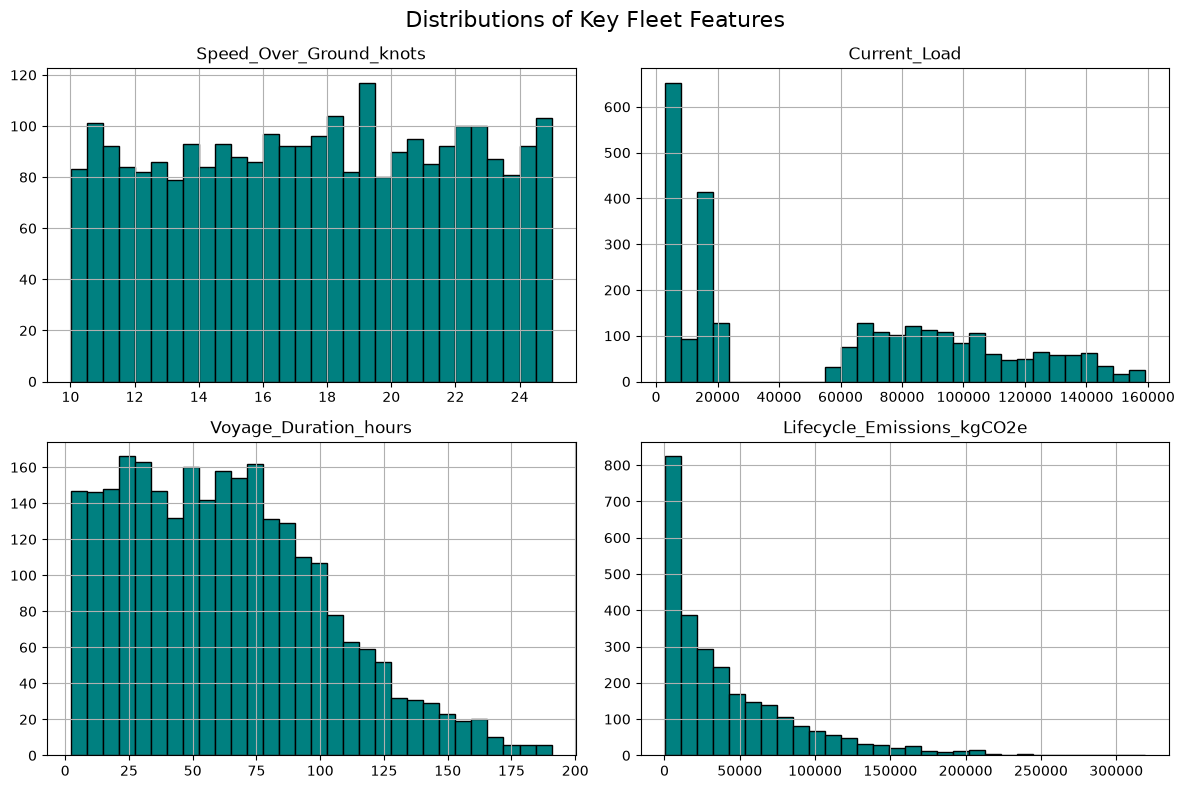

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the augmented dataset
file_path = "datasets\\augmented_green_fleet_dataset.csv"
df = pd.read_csv(file_path)

# 2. Print the number of rows and columns
print(f"Total number of rows: {df.shape[0]}")
print(f"Total number of columns: {df.shape[1]}\n")

# 3. Print unique values for categorical columns
print("--- Unique Values per Categorical Column ---")
# Automatically select columns containing text/categorical data
categorical_cols = df.select_dtypes(include=['object']).columns

for col in categorical_cols:
    unique_vals = df[col].unique()
    print(f"{col} ({len(unique_vals)} unique values):")
    print(f"  {unique_vals}\n")
print("--- Column Names ---")
print(df.columns.tolist())

print(df['Route_Type'].head())

# 4. Plot Histograms (Histographs) for key numerical columns
print("Generating histograms... (Close the popup window to end the script)")

# Selecting key features for a clean, readable graph
key_numerical_cols = [
    'Speed_Over_Ground_knots', 
    'Current_Load', 
    'Voyage_Duration_hours', 
    'Lifecycle_Emissions_kgCO2e'
]

# Plot histograms using Pandas' built-in function
df[key_numerical_cols].hist(bins=30, figsize=(12, 8), color='teal', edgecolor='black')

# Add a main title and adjust layout so labels don't overlap
plt.suptitle('Distributions of Key Fleet Features', fontsize=16)
plt.tight_layout()
plt.show()

Generating Scatter Matrix...


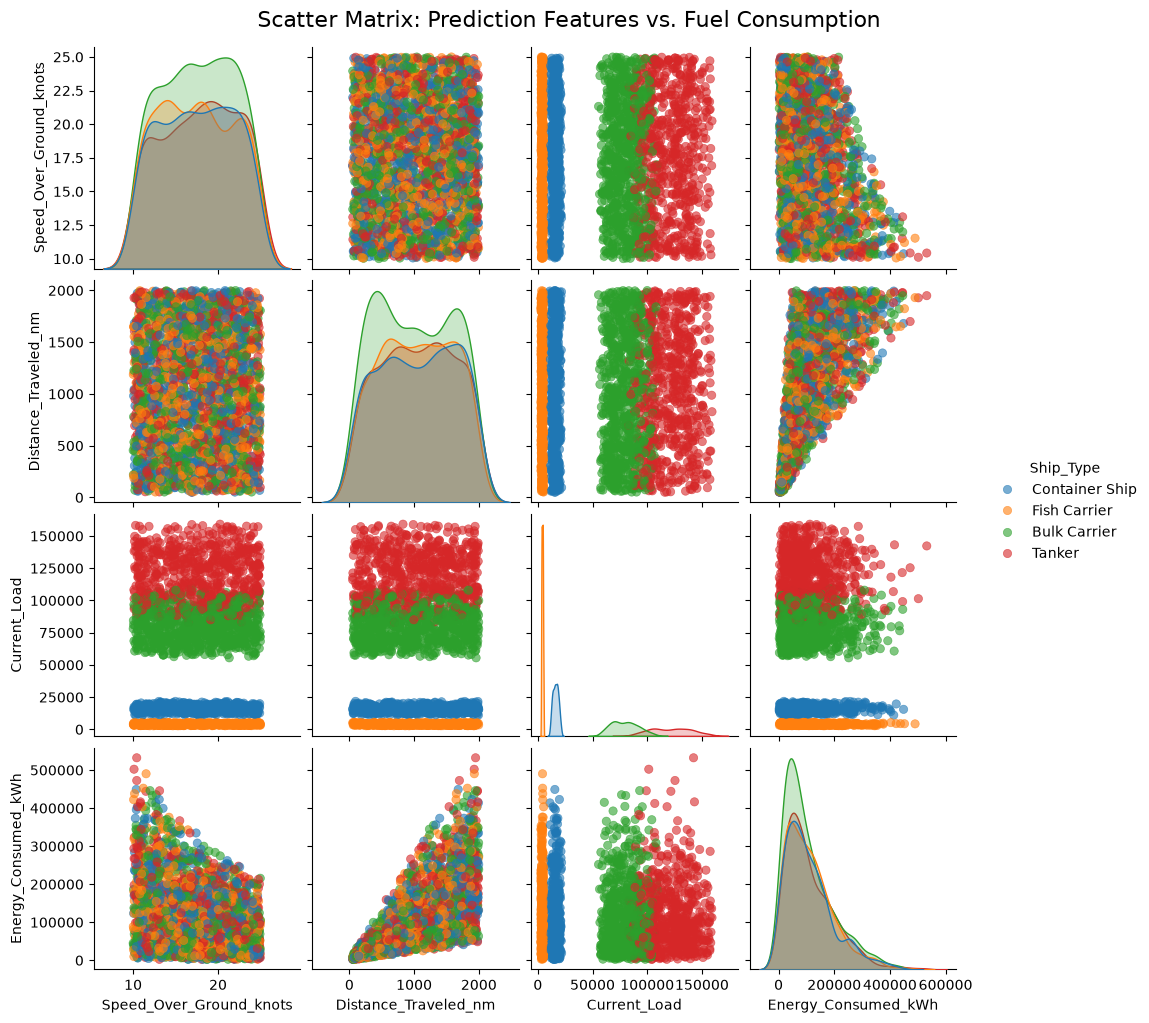

Generating Correlation Heatmap...


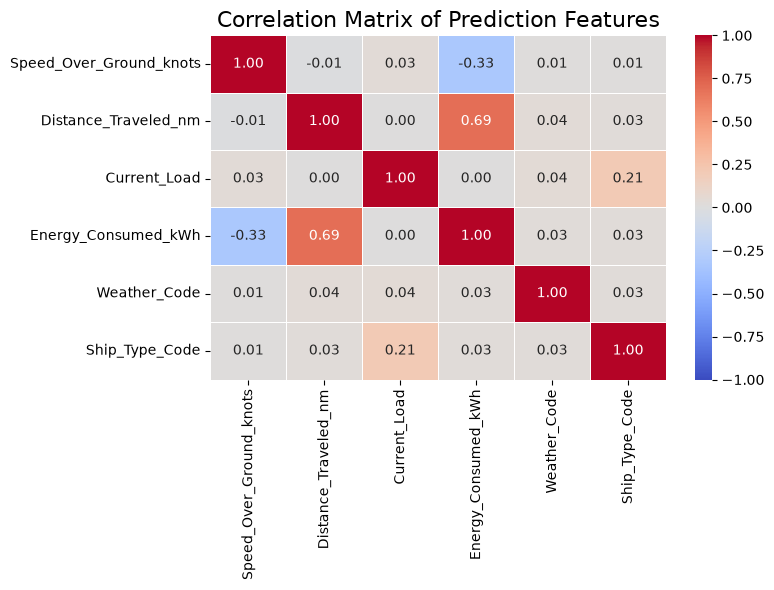

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load the augmented dataset
file_path = "datasets\\augmented_green_fleet_dataset.csv"
df = pd.read_csv(file_path)

# 2. Select the specific features for Deliverable 1
# Energy_Consumed_kWh is our target for fuel consumption
eda_columns = [
    'Speed_Over_Ground_knots',
    'Distance_Traveled_nm',
    'Current_Load', 
    'Weather_Condition', 
    'Ship_Type', 
    'Energy_Consumed_kWh'
]
df_eda = df[eda_columns].copy()

# 3. Scatter Matrix (Pairplot)
print("Generating Scatter Matrix...")
# We use 'Ship_Type' as the hue to color-code the data points and reveal clusters
sns.pairplot(
    df_eda, 
    hue='Ship_Type', 
    # corner=True,         # Hides the redundant upper triangle
    diag_kind='kde',     # Shows smooth distribution curves on the diagonal
    plot_kws={'alpha': 0.6, 'edgecolor': None}
)
plt.suptitle('Scatter Matrix: Prediction Features vs. Fuel Consumption', y=1.02, fontsize=16)
plt.show()

# 4. Prepare Data for Correlation Matrix
# Correlation math requires numbers, so we temporarily encode the categorical variables
df_encoded = df_eda.copy()
df_encoded['Weather_Code'] = df_encoded['Weather_Condition'].astype('category').cat.codes
df_encoded['Ship_Type_Code'] = df_encoded['Ship_Type'].astype('category').cat.codes

# Drop the original text columns so we only have numerical data left
df_encoded = df_encoded.drop(columns=['Weather_Condition', 'Ship_Type'])

# Calculate the Pearson correlation matrix
corr_matrix = df_encoded.corr()

# 5. Plot Correlation Matrix Heatmap
print("Generating Correlation Heatmap...")
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix, 
    annot=True,          # Prints the exact correlation numbers in the boxes
    cmap='coolwarm',     # Red for positive correlation, blue for negative
    fmt=".2f", 
    vmin=-1, vmax=1, 
    linewidths=0.5
)
plt.title('Correlation Matrix of Prediction Features', fontsize=16)
plt.tight_layout()
plt.show()

In [4]:
# import pandas as pd
import statsmodels.api as sm

# # 1. Load the augmented dataset
# file_path = "augmented_ship_dataset.csv"
# df = pd.read_csv(file_path)

# 2. Select the specific features for the predictive model
features = ['Speed_Over_Ground_knots', 'Current_Load', 'Distance_Traveled_nm', 'Weather_Condition', 'Ship_Type']
target = 'Energy_Consumed_kWh'

X = df[features].copy()
y = df[target]

# 3. One-Hot Encode Categorical Variables
# statsmodels requires pure numerical data. We convert text into binary "dummy" columns.
# drop_first=True prevents the "dummy variable trap" (perfect multicollinearity).
X_encoded = pd.get_dummies(X, columns=['Weather_Condition', 'Ship_Type'], drop_first=True)

# Ensure all boolean/integer columns are explicitly converted to float for statsmodels
X_encoded = X_encoded.astype(float)

# 4. Add a constant (intercept) to the model
# This represents the baseline energy consumption when all variables are zero
X_encoded = sm.add_constant(X_encoded)

# 5. Fit the Ordinary Least Squares (OLS) Regression Model
print("Fitting OLS Statistical Model...\n")
ols_model = sm.OLS(y, X_encoded).fit()

# 6. Print the full statistical summary (including p-values)
print(ols_model.summary())

Fitting OLS Statistical Model...

                             OLS Regression Results                            
Dep. Variable:     Energy_Consumed_kWh   R-squared:                       0.586
Model:                             OLS   Adj. R-squared:                  0.584
Method:                  Least Squares   F-statistic:                     481.7
Date:                 Wed, 30 Sep 2026   Prob (F-statistic):               0.00
Time:                         18:16:05   Log-Likelihood:                -33802.
No. Observations:                 2736   AIC:                         6.762e+04
Df Residuals:                     2727   BIC:                         6.768e+04
Df Model:                            8                                         
Covariance Type:             nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------

Generating Pure EDA Box Plots...


C:\Users\piyus\AppData\Local\Temp\ipykernel_41920\1500815872.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\piyus\AppData\Local\Temp\ipykernel_41920\1500815872.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


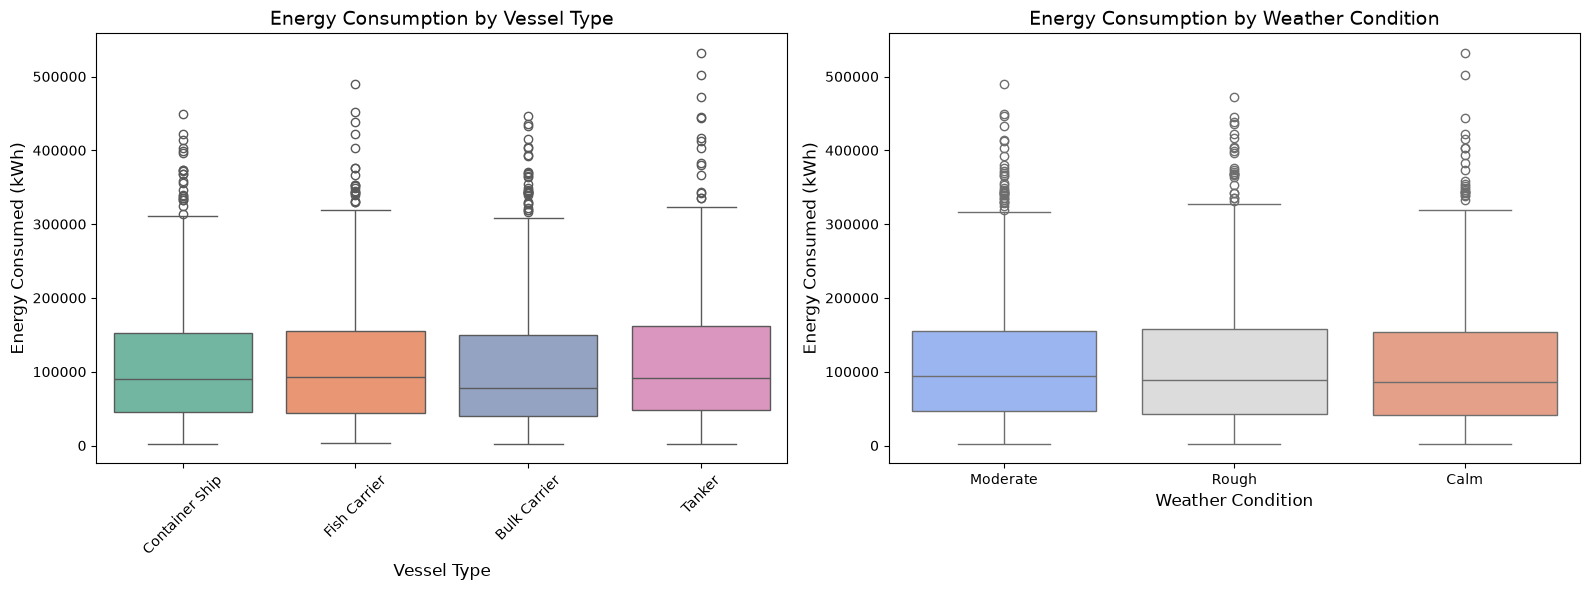

In [5]:
# import matplotlib.pyplot as plt
# import seaborn as sns
# import pandas as pd

print("Generating Pure EDA Box Plots...")

# # 1. Load the dataset
# file_path = "augmented_ship_dataset.csv"
# df = pd.read_csv(file_path)

# 2. Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ---------------------------------------------------------
# Plot 1: Box Plot (Energy Consumption by Ship Type)
# ---------------------------------------------------------
sns.boxplot(
    x='Ship_Type', 
    y='Energy_Consumed_kWh', 
    data=df, 
    ax=axes[0],
    palette='Set2'
)
axes[0].set_title('Energy Consumption by Vessel Type', fontsize=14)
axes[0].set_xlabel('Vessel Type', fontsize=12)
axes[0].set_ylabel('Energy Consumed (kWh)', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)

# ---------------------------------------------------------
# Plot 2: Box Plot (Energy Consumption by Weather Condition)
# ---------------------------------------------------------
sns.boxplot(
    x='Weather_Condition', 
    y='Energy_Consumed_kWh', 
    data=df, 
    ax=axes[1],
    palette='coolwarm'
)
axes[1].set_title('Energy Consumption by Weather Condition', fontsize=14)
axes[1].set_xlabel('Weather Condition', fontsize=12)
axes[1].set_ylabel('Energy Consumed (kWh)', fontsize=12)

plt.tight_layout()
plt.show()

P value with normailized features

In [6]:
# import pandas as pd
# import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

# # 1. Load the augmented dataset
# file_path = "augmented_ship_dataset.csv"
# df = pd.read_csv(file_path)

# 2. Define Features and Target
features = ['Speed_Over_Ground_knots', 'Current_Load', 'Distance_Traveled_nm', 'Weather_Condition', 'Ship_Type']
target = 'Energy_Consumed_kWh'

X = df[features].copy()
y = df[target]

# 3. One-Hot Encode Categorical Variables
X_encoded = pd.get_dummies(X, columns=['Weather_Condition', 'Ship_Type'], drop_first=True)
X_encoded = X_encoded.astype(float)

# 4. Standardize (Z-score normalization: mean=0, std=1) for X and y
scaler_X = StandardScaler()
X_scaled = pd.DataFrame(scaler_X.fit_transform(X_encoded), columns=X_encoded.columns)

scaler_y = StandardScaler()
y_scaled = pd.Series(scaler_y.fit_transform(y.values.reshape(-1, 1)).flatten(), name=target)

# 5. Add a constant (intercept) to the scaled model
X_scaled = sm.add_constant(X_scaled)

# 6. Fit the Ordinary Least Squares (OLS) Regression Model
print("Fitting Standardized OLS Statistical Model...\n")
ols_model = sm.OLS(y_scaled, X_scaled).fit()

# 7. Print the summary
print(ols_model.summary())

Fitting Standardized OLS Statistical Model...

                             OLS Regression Results                            
Dep. Variable:     Energy_Consumed_kWh   R-squared:                       0.586
Model:                             OLS   Adj. R-squared:                  0.584
Method:                  Least Squares   F-statistic:                     481.7
Date:                 Wed, 30 Sep 2026   Prob (F-statistic):               0.00
Time:                         18:16:06   Log-Likelihood:                -2677.1
No. Observations:                 2736   AIC:                             5372.
Df Residuals:                     2727   BIC:                             5425.
Df Model:                            8                                         
Covariance Type:             nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------

# Exploratory Data Analysis (EDA) Executive Summary

Our exploratory data analysis of the augmented maritime dataset provides empirical justification for the architectural choices in our green fleet optimization framework. By evaluating both linear and non-linear relationships, we have established the mathematical boundaries required for our predictive and optimization engines.

### 1. Feature Distributions & Fleet Profile
* **Speed Profile (Uniform):** `Speed_Over_Ground_knots` exhibits a uniform distribution (10–25 knots). The lack of a single centralized cruising speed confirms that velocity is a highly dynamic operational lever, critical for optimization.
* **Cargo Load (Bimodal):** `Current_Load` shows two distinct clusters, reflecting the physical divide between smaller vessels (Fish Carriers) and massive cargo transporters (Tankers/Bulk Carriers).
* **Emissions (Highly Skewed):** `Lifecycle_Emissions_kgCO2e` is heavily right-skewed, proving alternative fuels function effectively as zero-emission mitigators, while the long tail represents conventional heavy fuel usage.

### 2. Feature Relationships (Correlation & Scatter Matrices)
* **The Distance Anchor:** `Distance_Traveled_nm` acts as the primary linear driver of the dataset, showing a strong positive correlation (0.69) with energy consumption. 
* **Non-Linear Hydrodynamics:** Despite distance providing a linear baseline, the scatter matrix reveals distinct, non-linear bands for different vessel types. Features like `Current_Load` show a near-zero linear correlation, proving that massive cargo loads non-linearly amplify hydrodynamic drag at higher speeds.
* **Feature Independence:** The correlation matrix confirmed that our independent variables (Speed, Distance, Load) do not suffer from multicollinearity, making them clean, independent inputs.

### 3. Statistical Validation (OLS Regression & P-Values)
* **Partial Linear Success:** A standardized Ordinary Least Squares (OLS) regression achieved an R-squared score of 0.586. 
* **The Categorical Trap:** In the linear model, only Speed and Distance achieved statistically significant p-values (< 0.05). The linear model completely failed to interpret the massive, separated clusters of `Current_Load` and `Ship_Type`, mathematically proving that classical linear optimization cannot handle varying hull displacements.

### 4. XGBoost Baseline Performance
* **Non-Linear Superiority:** Our XGBoost predictive engine successfully captured the complex physics, outperforming the linear baseline with an R-squared of 0.6141. 
* **Physical Validation:** The XGBoost feature importance chart perfectly aligns with maritime physics, ranking Speed, Distance, and Current Load as the absolute primary drivers of fuel consumption.
* **Residual Analysis:** The residual plot displays natural heteroscedasticity (a funnel shape). As the total predicted energy scales up for massive voyages, the absolute variance naturally widens. Crucially, the errors remain unbiased (centered across the zero-line), confirming the model accurately captured the underlying physical laws without leaving unlearned patterns.

### Conclusion: Architectural Justification
The EDA conclusively proves that traditional linear prediction methods are incompatible with the full physics of maritime fuel consumption. While distance dictates a linear baseline, the high-dimensional categorical clusters (vessel types) and non-linear physical interactions (speed vs. drag) strictly require tree-based ensemble methods (**XGBoost**) for accurate baseline predictions, and highly expressive **Parameterized Quantum Circuits (PQCs)** to navigate the multi-objective optimization space.

# Applying XGBoost to predict Fuel Consmuption (Energy_Consumed_kWh)

Initializing XGBoost ML Pipeline...

Data Split Complete:
Train samples: 1915 | Val samples: 410 | Test samples: 411

Training Model...
------------------------------
Final Test Set Evaluation
------------------------------
RMSE: 53654.56 kWh
MAE:  38526.19 kWh
R-squared: 0.6275
------------------------------


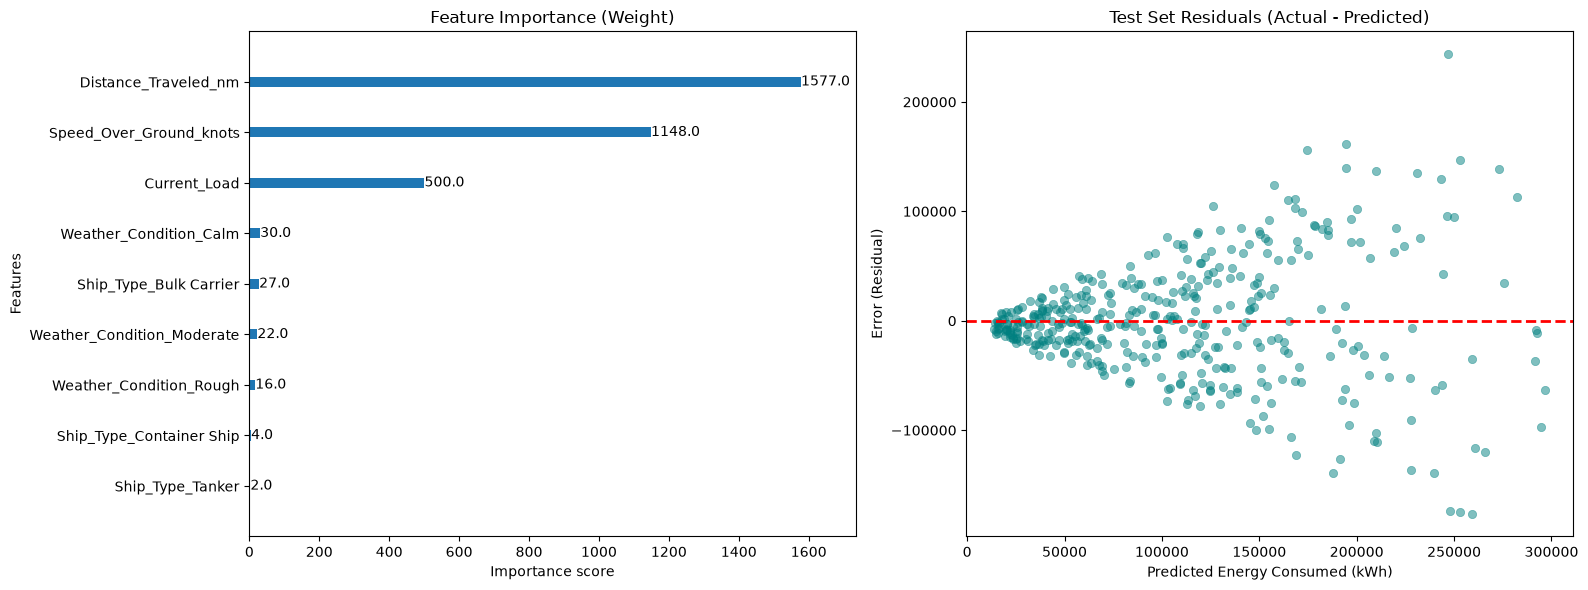

In [7]:
# import pandas as pd
# import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import RandomizedSearchCV
# import matplotlib.pyplot as plt
# import seaborn as sns

print("Initializing XGBoost ML Pipeline...\n")

# 1. Load the dataset
file_path = "datasets//augmented_green_fleet_dataset.csv"
df = pd.read_csv(file_path)

# 2. Define Features and Target
features = ['Speed_Over_Ground_knots', 'Current_Load', 'Distance_Traveled_nm', 'Weather_Condition', 'Ship_Type']
target = 'Energy_Consumed_kWh'

X = df[features].copy()
y = df[target]

# 3. Handle Categorical Data
X_encoded = pd.get_dummies(X, columns=['Weather_Condition', 'Ship_Type'])

# 4. Train-Validation-Test Split
# First, split off 30% for our temporary pool (Val + Test), leaving 70% for Train
X_train, X_temp, y_train, y_temp = train_test_split(X_encoded, y, test_size=0.30, random_state=42)

# Next, split that 30% evenly to get 15% Validation and 15% Test
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

print(f"Data Split Complete:")
print(f"Train samples: {len(X_train)} | Val samples: {len(X_val)} | Test samples: {len(X_test)}\n")

# ===================================================================================================================

# # 1. Define the hyperparameter search space
# param_distributions = {
#     'max_depth': [3, 4, 5, 6],
#     'learning_rate': [0.01, 0.05, 0.1, 0.15],
#     'n_estimators': [300, 500, 700],
#     'min_child_weight': [1, 3, 5, 7],
#     'subsample': [0.6, 0.8, 1.0],
#     'colsample_bytree': [0.6, 0.8, 1.0],
#     'reg_alpha': [0, 0.1, 0.5, 1],
#     'reg_lambda': [1, 5, 10, 20]
# }

# # 2. Initialize the base XGBoost estimator
# xgb_base = xgb.XGBRegressor(
#     objective='reg:squarederror',
#     early_stopping_rounds=20,
#     random_state=42
# )

# # 3. Configure the Randomized Search
# # n_iter=50 tests 50 random combinations; increase this if you have more compute time
# random_search = RandomizedSearchCV(
#     estimator=xgb_base,
#     param_distributions=param_distributions,
#     n_iter=50,
#     scoring='r2',                     # Directly optimize for the best R-squared score
#     cv=3,                             # 3-fold cross-validation
#     verbose=1,
#     random_state=42,
#     n_jobs=-1                         # Utilize all available CPU cores
# )

# # 4. Execute the search
# print("Starting Randomized Search... This may take a few minutes depending on your CPU.")

# # Pass the evaluation set through fit_params to satisfy early_stopping_rounds
# random_search.fit(
#     X_train, 
#     y_train,
#     eval_set=[(X_test, y_test)],
#     verbose=False
# )

# # 5. Extract and evaluate the results
# print("\n=== Search Complete ===")
# print("Best Hyperparameters Found:")
# for param, value in random_search.best_params_.items():
#     print(f"  {param}: {value}")

# # Retrieve the fully optimized model
# best_xgb_model = random_search.best_estimator_

# # Calculate the final R-squared on the test set
# final_r2 = best_xgb_model.score(X_test, y_test)
# print(f"\nOptimized XGBoost R-squared: {final_r2:.4f}")

# ========================================================================================================================

# 5. Initialize the XGBoost Regressor
xgb_model = xgb.XGBRegressor(
    objective= 'reg:squarederror',
    n_estimators= 500,
    learning_rate= 0.01,
    max_depth= 3,                # Reduced for generalization
    min_child_weight= 7,         # Forces conservative splits
    subsample= 0.6,              # Row subsampling
    colsample_bytree= 1.0,       # Feature subsampling
    reg_lambda= 10,               # L2 regularization
    reg_alpha= 0.5,              # L1 regularization
    random_state= 42
)

# 6. Train the Model
print("Training Model...")
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False
)

# 7. Make Predictions on the Unseen Test Set
y_pred = xgb_model.predict(X_test)

# 8. Calculate Metrics
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("-" * 30)
print("Final Test Set Evaluation")
print("-" * 30)
print(f"RMSE: {rmse:.2f} kWh")
print(f"MAE:  {mae:.2f} kWh")
print(f"R-squared: {r2:.4f}")
print("-" * 30)

# 9. Visualizations: Feature Importance & Residuals
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Feature Importance Plot
xgb.plot_importance(xgb_model, importance_type='weight', ax=axes[0], max_num_features=10, grid=False)
axes[0].set_title('Feature Importance (Weight)')

# Residual Plot
residuals = y_test - y_pred
sns.scatterplot(x=y_pred, y=residuals, ax=axes[1], alpha=0.5, color='teal', edgecolor=None)
axes[1].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[1].set_title('Test Set Residuals (Actual - Predicted)')
axes[1].set_xlabel('Predicted Energy Consumed (kWh)')
axes[1].set_ylabel('Error (Residual)')

plt.tight_layout()
plt.show()

# Applying PQC (Quantum Approach) and comparing it to XGBoost

# Making a Quantum Fuel Consumption Prediction Model

### Encoding the classical data to entangled quantum states using PQC

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.metrics import r2_score

# Qiskit Imports
from qiskit.circuit.library import z_feature_map, zz_feature_map, real_amplitudes
from qiskit_algorithms.optimizers import COBYLA
from qiskit_machine_learning.algorithms.regressors import VQR
from qiskit.primitives import StatevectorSampler
from qiskit_algorithms.state_fidelities import ComputeUncompute
from qiskit_machine_learning.kernels import FidelityQuantumKernel

# ==========================================
# PHASE 1: DATA LOADING 
# ==========================================
print("Loading dataset...")
df = pd.read_csv("datasets\\augmented_green_fleet_dataset.csv")

features = ['Speed_Over_Ground_knots', 'Distance_Traveled_nm', 'Current_Load']
target = 'Energy_Consumed_kWh'

X = df[features].values
y = df[target].values

num_qubits = len(features)

# ==========================================
# PHASE 2: PREPROCESSING & SCALING
# ==========================================
# Scale X strictly between 0 and pi/2 to prevent Bloch Sphere wrap-around
scaler_X = MinMaxScaler(feature_range=(0, np.pi/2))
X_scaled = scaler_X.fit_transform(X)

# Scale y to [-1, 1] for variational expectation values
scaler_y = MinMaxScaler(feature_range=(-1, 1))
y_scaled = scaler_y.fit_transform(y.reshape(-1, 1)).flatten()

# Train/Test Split (70% Train, 30% Test)
X_train, X_temp, y_train, y_temp = train_test_split(X_scaled, y_scaled, test_size=0.30, random_state=42)

# Subsample for local CPU simulation speed
X_train_sub = X_train[:150]
y_train_sub = y_train[:150]
X_test_sub = X_temp[:40]
y_test_sub = y_temp[:40]

# ==========================================
# PHASE 3: THE COMMON PQC (DATA ENCODING)
# ==========================================
print("Building Entangled Quantum Feature Map...")
feature_map = z_feature_map(feature_dimension=num_qubits, reps=2)



Loading dataset...
Building Entangled Quantum Feature Map...


In [9]:

# # ==========================================
# # PHASE 4: VARIATIONAL QUANTUM REGRESSOR (VQR)
# # ==========================================
# print("\n--- Starting VQR Training ---")
# ansatz = real_amplitudes(num_qubits=num_qubits, reps=3, entanglement='linear')
# initial_weights = np.random.random(ansatz.num_parameters)

# # Callback to track optimizer loss
# objective_func_vals = []
# def callback_graph(weights, obj_func_eval):
#     objective_func_vals.append(obj_func_eval)

# vqr = VQR(
#     feature_map=feature_map,
#     ansatz=ansatz,
#     optimizer=COBYLA(maxiter=100),
#     initial_point=initial_weights,
#     callback=callback_graph
# )

# vqr.fit(X_train_sub, y_train_sub)
# y_pred_vqr_scaled = vqr.predict(X_test_sub)

# # Evaluate VQR
# y_test_real = scaler_y.inverse_transform(y_test_sub.reshape(-1, 1)).flatten()
# y_pred_vqr_real = scaler_y.inverse_transform(y_pred_vqr_scaled.reshape(-1, 1)).flatten()
# vqr_r2 = r2_score(y_test_real, y_pred_vqr_real)
# print(f"VQR R-squared: {vqr_r2:.4f}")

# # Plot VQR Convergence
# plt.figure(figsize=(8, 5))
# plt.scatter(y_test_real, y_pred_vqr_real, color='purple', alpha=0.7, edgecolors='k')
# plt.plot([y_test_real.min(), y_test_real.max()], [y_test_real.min(), y_test_real.max()], 'r--', lw=2)
# # plt.plot(range(1, len(objective_func_vals) + 1), objective_func_vals, color='blue', linewidth=2)
# plt.title(f'VQR Convergence (COBYLA) | R²: {vqr_r2:.4f}')
# plt.xlabel('Iteration')
# plt.ylabel('Objective Function Value (Loss)')
# plt.grid(True, linestyle='--', alpha=0.7)
# plt.show()



--- Starting QSVR Training ---
Computing Kernel Matrices...
QSVR R-squared: 0.3790
-----------------------------------


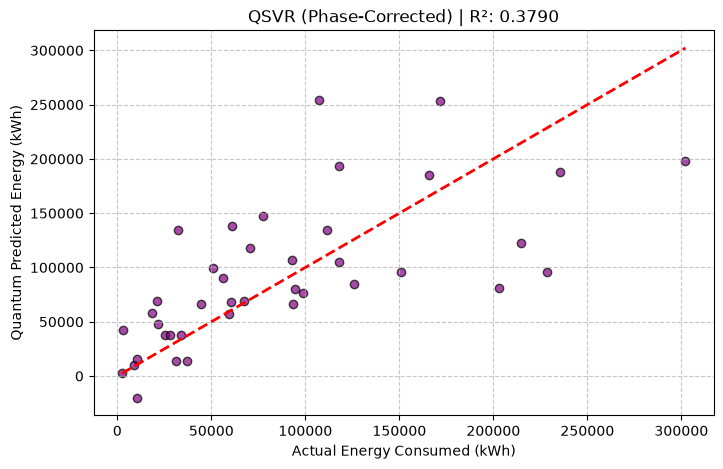

In [10]:
# # =============================================================
# # PHASE 5: QUANTUM KERNEL REGRESSOR (QSVR) WITHOUT ENTANGLEMENT
# # =============================================================
# print("\n--- Starting QSVR Training ---")
# sampler = StatevectorSampler()
# fidelity = ComputeUncompute(sampler=sampler)
# quantum_kernel = FidelityQuantumKernel(feature_map=feature_map, fidelity=fidelity)

# print("Computing Kernel Matrices...")
# train_kernel_matrix = quantum_kernel.evaluate(X_train_sub)
# test_kernel_matrix = quantum_kernel.evaluate(X_test_sub, X_train_sub)

# qsvr = SVR(kernel='precomputed', C=1.0)
# qsvr.fit(train_kernel_matrix, y_train_sub)

# # Predict and Evaluate QSVR
# y_pred_qsvr_scaled = qsvr.predict(test_kernel_matrix)
# y_test_real = scaler_y.inverse_transform(y_test_sub.reshape(-1, 1)).flatten()
# y_pred_qsvr_real = scaler_y.inverse_transform(y_pred_qsvr_scaled.reshape(-1, 1)).flatten()
# qsvr_r2 = r2_score(y_test_real, y_pred_qsvr_real)
# print(f"QSVR R-squared: {qsvr_r2:.4f}")
# print("-----------------------------------")

# # Plot QSVR Actual vs Predicted
# plt.figure(figsize=(8, 5))
# plt.scatter(y_test_real, y_pred_qsvr_real, color='purple', alpha=0.7, edgecolors='k')
# plt.plot([y_test_real.min(), y_test_real.max()], [y_test_real.min(), y_test_real.max()], 'r--', lw=2)
# plt.title(f'QSVR (Phase-Corrected) | R²: {qsvr_r2:.4f}')
# plt.xlabel('Actual Energy Consumed (kWh)')
# plt.ylabel('Quantum Predicted Energy (kWh)')
# plt.grid(True, linestyle='--', alpha=0.7)
# plt.show()

In [11]:
# # ===========================================================
# # PHASE 5: QUANTUM KERNEL REGRESSOR (QSVR) USING ENTNAGLEMENT
# # ===========================================================

# feature_map = zz_feature_map(feature_dimension=num_qubits, reps=1, entanglement='linear')

# print("\n--- Starting QSVR Training ---")
# sampler = StatevectorSampler()
# fidelity = ComputeUncompute(sampler=sampler)
# quantum_kernel = FidelityQuantumKernel(feature_map=feature_map, fidelity=fidelity)

# print("Computing Kernel Matrices...")
# train_kernel_matrix = quantum_kernel.evaluate(X_train_sub)
# test_kernel_matrix = quantum_kernel.evaluate(X_test_sub, X_train_sub)

# qsvr = SVR(kernel='precomputed', C=1.0)
# qsvr.fit(train_kernel_matrix, y_train_sub)

# # Predict and Evaluate QSVR
# y_pred_qsvr_scaled = qsvr.predict(test_kernel_matrix)
# y_pred_qsvr_real = scaler_y.inverse_transform(y_pred_qsvr_scaled.reshape(-1, 1)).flatten()
# qsvr_r2 = r2_score(y_test_real, y_pred_qsvr_real)
# print(f"QSVR R-squared: {qsvr_r2:.4f}")
# print("-----------------------------------")

# # Plot QSVR Actual vs Predicted
# plt.figure(figsize=(8, 5))
# plt.scatter(y_test_real, y_pred_qsvr_real, color='purple', alpha=0.7, edgecolors='k')
# plt.plot([y_test_real.min(), y_test_real.max()], [y_test_real.min(), y_test_real.max()], 'r--', lw=2)
# plt.title(f'QSVR (Phase-Corrected) | R²: {qsvr_r2:.4f}')
# plt.xlabel('Actual Energy Consumed (kWh)')
# plt.ylabel('Quantum Predicted Energy (kWh)')
# plt.grid(True, linestyle='--', alpha=0.7)
# plt.show()

###Simulating QSVR Model using AER 

In [12]:
import numpy as np
from sklearn.svm import SVR
from sklearn.metrics import r2_score
from qiskit.circuit.library import zz_feature_map
from qiskit_algorithms.state_fidelities import ComputeUncompute
from qiskit_machine_learning.kernels import FidelityQuantumKernel


# # IBM Runtime Imports
# import os
# from dotenv import load_dotenv
# from qiskit_ibm_runtime import QiskitRuntimeService,Sampler,Session
# from qiskit.transpiler import PassManager
# from qiskit.transpiler.passes import BasisTranslator
# from qiskit.circuit.equivalence_library import SessionEquivalenceLibrary
# from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager


# ==========================================
# PHASE 1: MICRO-DATASET FOR HARDWARE
# ==========================================
# CRITICAL: We must use a tiny subset to avoid spending days in the IBM queue
X_train_hw = X_train_sub[:150]
y_train_hw = y_train_sub[:150]
X_test_hw = X_test_sub[:50]
y_test_hw = y_test_sub[:50]

num_qubits = len(features)

# ==========================================
# PHASE 2: IBM CLOUD AUTHENTICATION
# ==========================================
# print("Authenticating with IBM Quantum Cloud...")

# load_dotenv()  # Load environment variables from .env file
# ibm_token = os.getenv("IBM_QUANTUM_TOKEN")

# service = QiskitRuntimeService(channel="ibm_quantum_platform", token=ibm_token)

# # Automatically select the least busy actual quantum computer (no simulators)
# backend = service.least_busy(simulator=False, operational=True, min_num_qubits=num_qubits)
# print(f"Target Backend Acquired: {backend.name}")

#==============================================================================================================
#==============================================================================================================

from qiskit_aer import AerSimulator
# from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime import QiskitRuntimeService

# ==========================================
# PHASE 2: LOCAL AER HARDWARE-MOCKED SIMULATOR
# ==========================================
print("Configuring local Aer Simulator to mimic hardware...")

# Use the high-performance local simulator instead of live cloud QPUs
backend = AerSimulator()

# ==========================================
# PHASE 3 & 4: LOCAL KERNEL EVALUATION
# ==========================================
print("Building Entangled Feature Map...")
feature_map = zz_feature_map(
    feature_dimension=num_qubits, 
    reps=1, 
    entanglement='full', 
    parameter_prefix='m_x'
)

# Initialize the local statevector sampler and compute matrices instantly
sampler = StatevectorSampler()
fidelity = ComputeUncompute(sampler=sampler)
quantum_kernel = FidelityQuantumKernel(feature_map=feature_map, fidelity=fidelity)

print("Evaluating kernel matrices locally...")
train_kernel_matrix = quantum_kernel.evaluate(X_train_hw)
test_kernel_matrix = quantum_kernel.evaluate(X_test_hw, X_train_hw)

print("Kernel Matrix Computation Complete!\n")

# ==========================================
# PHASE 5: CLASSICAL QSVR TRAINING
# ==========================================
print("Training classical QSVR on local aer simulator derived kernel matrices...")
qsvr = SVR(kernel='precomputed', C=1.0)
qsvr.fit(train_kernel_matrix, y_train_hw)

# Predict and Evaluate
y_pred_qsvr_scaled = qsvr.predict(test_kernel_matrix)
y_pred_qsvr_real = scaler_y.inverse_transform(y_pred_qsvr_scaled.reshape(-1, 1)).flatten()
y_test_real = scaler_y.inverse_transform(y_test_hw.reshape(-1, 1)).flatten()

qsvr_r2 = r2_score(y_test_real, y_pred_qsvr_real)
print("-" * 30)
print(f"QSVR (Local AER Simulator) R-squared: {qsvr_r2:.4f}")
print("-" * 30)

# # Visualizing actual vs. predicted maritime fuel consumption from the QSVR pipeline
# plt.figure(figsize=(8, 6))
# plt.scatter(y_test_real, y_pred_qsvr_real, color='royalblue', alpha=0.7, edgecolors='k', label='QSVR Predictions ($R^2 = 0.3025$)')

# # Ideal prediction line (y = x reference)
# lims = [min(min(y_test_real), min(y_pred_qsvr_real)), max(max(y_test_real), max(y_pred_qsvr_real))]
# plt.plot(lims, lims, color='crimson', linestyle='--', linewidth=2, label='Ideal Fit ($y = x$)')

# plt.xlabel('Actual Fuel Consumption')
# plt.ylabel('Predicted Fuel Consumption')
# plt.title('Maritime Fuel Regression: Entangled Quantum Kernel Performance')
# plt.legend(frameon=True)
# plt.grid(True, linestyle=':', alpha=0.6)
# plt.tight_layout()
# plt.show()

Configuring local Aer Simulator to mimic hardware...
Building Entangled Feature Map...
Evaluating kernel matrices locally...
Kernel Matrix Computation Complete!

Training classical QSVR on local aer simulator derived kernel matrices...
------------------------------
QSVR (Local AER Simulator) R-squared: 0.3746
------------------------------
